# D009 종합 프로젝트 — 빵셀러 데이터 정제·변환·저장 파이프라인

| 항목 | 내용 |
|---|---|
| 분석 목적 | 빵셀러(베이커리 체인 6개 매장) 3개월 운영 데이터를 정제해 월·매장 / 상품별 KPI를 만들고 Parquet으로 넘긴다 |
| 데이터 출처 | (가상) 빵셀러 운영 로그 — D009 코드 3으로 생성 |
| 작성자 | 서원민 |
| 작성일 | 2026년 10월 27일 |

**흐름**: 준비 → 데이터 생성(인제스트) → 시나리오 1 품질 진단 → 시나리오 2 정제 파이프라인 → 저장 비교(CSV vs Parquet) → 시나리오 3 KPI 변환·Parquet 저장 → EDA → 코드 퀴즈 → 결정 로그 → 보고서

## 0. 준비 — 라이브러리 · 출력 폴더

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

# 제출 구조에 맞춘 출력 폴더: D009/outputs/
OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)
print("pandas", pd.__version__, "/ 출력 경로:", OUT_DIR.resolve())

pandas 3.0.2 / 출력 경로: /home/claude/bk/outputs


## 1. 인제스트 — 빵셀러 데이터 생성 (코드 3)

In [2]:
# 종합 프로젝트용 새 데이터 생성 — 베이커리 체인 "빵셀러" 운영 데이터
np.random.seed(13)
n_days = 90
n_stores = 6
n_rows = n_days * n_stores * 4   # 매장 x 일자 x 시간대(4구간)

stores = [f"S{i:02d}" for i in range(1, n_stores + 1)]
items = ["크루아상", "식빵", "케이크", "샌드위치", "쿠키"]

bakery = pd.DataFrame({
    "store_id": np.tile(stores, n_rows // n_stores)[:n_rows],
    "date_str": np.random.choice([
        "2025-04-01", "2025/04/01", "20250401",
        "2025-05-15", "2025/05/15", "20250515",
        "2025-06-20", "2025/06/20", "20250620",
    ], n_rows),
    "item": np.random.choice(items, n_rows),
    "quantity": np.random.choice([1, 1, 2, 2, 3, 5, 50], n_rows),  # 50은 의심값
    "unit_price": np.random.choice([3500, 4500, 5500, 8500, 12000], n_rows),
})
bakery["revenue"] = bakery["quantity"] * bakery["unit_price"]

# 오염 심기
bakery.loc[np.random.choice(n_rows, 60, replace=False), "revenue"] = np.nan
bakery.loc[5, "revenue"] = -45000  # 환불 또는 실수
bakery.loc[bakery.sample(10, random_state=1).index, "store_id"] = " S01 "  # 공백
bakery.loc[bakery.sample(8, random_state=2).index, "item"] = "케익"        # 표기 혼재('케이크' vs '케익')
bakery = pd.concat([bakery, bakery.iloc[[0, 1, 2, 3]]], ignore_index=True)   # 중복 4건

print("빵셀러 데이터 생성 완료:", bakery.shape)
bakery.head()

빵셀러 데이터 생성 완료: (2164, 6)


,store_id,date_str,item,quantity,unit_price,revenue
0,S01,20250401,쿠키,2,12000,24000.0
1,S02,2025-04-01,케이크,2,12000,24000.0
2,S03,2025-04-01,쿠키,1,5500,5500.0
3,S04,2025-06-20,쿠키,2,8500,17000.0
4,S05,20250401,샌드위치,5,4500,22500.0


---
## 시나리오 1 — 품질 진단 (Part 2 적용)

`quality_report_full()`을 `bakery`에 적용해 답합니다.

1. 결측률이 가장 높은 컬럼은?
2. `maybe_datetime`이 True로 잡힌 컬럼이 있나요?
3. 수치형 중 IQR 이상치 비율이 가장 높은 컬럼은?

In [3]:
def quality_report_full(df: pd.DataFrame, name: str = "df") -> pd.DataFrame:
    '''결측·중복·타입 + 수치형 IQR 이상치 비율 + 날짜로 보이는 문자열 컬럼을 한 표로 진단합니다.'''
    base = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing": df.isna().sum(),
        "missing_pct": (df.isna().mean() * 100).round(2),
        "n_unique": df.nunique(dropna=True),
    })

    # IQR 이상치 비율 (수치형 컬럼만)
    outlier_pct = {}
    for col in df.select_dtypes(include="number").columns:
        s = df[col].dropna()
        q1, q3 = s.quantile(0.25), s.quantile(0.75)
        iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        outlier_pct[col] = ((s < lo) | (s > hi)).mean() * 100
    base["outlier_pct_iqr"] = pd.Series(outlier_pct).round(2)

    # 문자열 컬럼이 실제로는 날짜인지 의심 표시
    # 판단 근거: 포맷이 섞여 있으면 format 없이는 첫 값의 포맷만 추론해 나머지가 NaT가 됨
    #           → format="mixed"로 시도해야 날짜 컬럼을 놓치지 않음
    suspicious_datetime = []
    for col in df.select_dtypes(include=["object", "string"]).columns:
        parsed = pd.to_datetime(df[col], format="mixed", errors="coerce")
        if parsed.notna().mean() > 0.8:
            suspicious_datetime.append(col)
    base["maybe_datetime"] = base.index.isin(suspicious_datetime)

    print(f"[품질 리포트(완전판)] {name}")
    print(f"  행 수: {len(df):,}  /  열 수: {df.shape[1]}")
    print(f"  메모리: {df.memory_usage(deep=True).sum() / 1024:.1f} KB")
    print(f"  완전 중복 행: {df.duplicated().sum()}건")
    if suspicious_datetime:
        print(f"  📌 날짜로 보이는 문자열 컬럼: {suspicious_datetime}")
    return base


qr_bakery = quality_report_full(bakery, "bakery")
qr_bakery

[품질 리포트(완전판)] bakery
  행 수: 2,164  /  열 수: 6
  메모리: 146.5 KB
  완전 중복 행: 321건
  📌 날짜로 보이는 문자열 컬럼: ['date_str']


,dtype,missing,missing_pct,n_unique,outlier_pct_iqr,maybe_datetime
store_id,str,0,0.00,7,NaN,False
date_str,str,0,0.00,9,NaN,True
item,str,0,0.00,6,NaN,False
quantity,int64,0,0.00,5,14.56,False
unit_price,int64,0,0.00,5,0.00,False
revenue,float64,60,2.77,26,17.30,False


In [4]:
q1 = qr_bakery["missing_pct"].idxmax()
q2 = qr_bakery.index[qr_bakery["maybe_datetime"]].tolist()
q3 = qr_bakery["outlier_pct_iqr"].idxmax()

print(f"Q1. 결측률 최고 컬럼     : {q1} ({qr_bakery.loc[q1, 'missing_pct']}%, {qr_bakery.loc[q1, 'missing']}건)")
print(f"Q2. maybe_datetime=True : {q2}")
print(f"Q3. IQR 이상치 비율 최고 : {q3} ({qr_bakery.loc[q3, 'outlier_pct_iqr']}%)")

print("\n[추가 점검] 표기 혼재 · 극단값")
print("  store_id :", bakery["store_id"].value_counts().to_dict())
print("  item     :", bakery["item"].value_counts().to_dict())
print("  quantity :", bakery["quantity"].value_counts().sort_index().to_dict())
print("  revenue<0:", bakery.loc[bakery["revenue"] < 0, "revenue"].tolist())
print("  date_str 고유값:", sorted(bakery["date_str"].unique()))

# 포맷 지정 없이 파싱하면 어떻게 되는지 비교 (errors='coerce'가 실패를 숨기는 예)
plain = pd.to_datetime(bakery["date_str"], errors="coerce")
print(f"\n[비교] format 없이 파싱 성공률: {plain.notna().mean() * 100:.1f}%  →  format='mixed': "
      f"{pd.to_datetime(bakery['date_str'], format='mixed', errors='coerce').notna().mean() * 100:.1f}%")

Q1. 결측률 최고 컬럼     : revenue (2.77%, 60건)
Q2. maybe_datetime=True : ['date_str']
Q3. IQR 이상치 비율 최고 : revenue (17.3%)

[추가 점검] 표기 혼재 · 극단값
  store_id : {'S02': 361, 'S04': 361, 'S01': 360, 'S03': 358, 'S05': 357, 'S06': 357, ' S01 ': 10}
  item     : {'쿠키': 446, '샌드위치': 443, '식빵': 435, '케이크': 417, '크루아상': 415, '케익': 8}
  quantity : {1: 609, 2: 619, 3: 343, 5: 278, 50: 315}
  revenue<0: [-45000.0]
  date_str 고유값: ['2025-04-01', '2025-05-15', '2025-06-20', '2025/04/01', '2025/05/15', '2025/06/20', '20250401', '20250515', '20250620']

[비교] format 없이 파싱 성공률: 34.5%  →  format='mixed': 100.0%


**읽는 법**

- **Q1** 결측률이 가장 높은 컬럼은 `revenue`입니다. 매출이 비어 있으면 집계에서 빠지므로 처리 방침이 필요합니다.
- **Q2** `date_str`이 `maybe_datetime=True`로 잡힙니다. 단, 포맷 3종이 섞여 있어서 `format` 없이 파싱하면 성공률이 약 1/3에 그쳐 **날짜 컬럼인데도 False로 잘못 나옵니다.** 그래서 진단 함수 안에서 `format="mixed"`를 썼습니다.
- **Q3** IQR 이상치 비율은 `revenue`(17.3%)가 가장 높고 `quantity`(14.56%)가 그다음입니다. 둘 다 원인은 같습니다. quantity=50이 전체의 약 15%나 되어 revenue에도 큰 값이 그만큼 생깁니다. 모범 답안의 "quantity가 가장 높다"는 설명과 실제 결과가 다르니, 직접 실행한 숫자를 기준으로 답합니다. 50이 이렇게 흔하면 "드문 오류"라기보다 단체 주문일 가능성도 있습니다.
- 완전 중복이 심어 둔 4건보다 훨씬 많이 잡힙니다. 거래 ID·시각 컬럼이 없어 **같은 날 같은 상품을 같은 수량으로 판 정상 거래**도 완전 중복으로 보이기 때문입니다. (→ 결정 로그·한계에 기록)

---
## 시나리오 2 — 정제 파이프라인 (Part 3·6 적용)

6단계를 작은 함수로 나누고 `.pipe()`로 묶어 `bakery_clean`을 만듭니다. 각 단계 함수가 **결정 로그를 스스로 기록**하도록 했습니다(심화 과제: `log_decision` 자동 호출).

1. 완전 중복 제거 → 2. `store_id` 공백 제거 → 3. `'케익'` → `'케이크'` → 4. `date_str` → `date` 파싱 → 5. `revenue < 0` → `refunds_bakery` 분리 → 6. `revenue` 결측 제거

In [5]:
decisions = []          # 결정 로그 누적
refunds_bakery = pd.DataFrame()


def log_decision(step: str, action: str, reason: str, result: str):
    decisions.append({"step": step, "action": action, "reason": reason, "result": result})


def b_dedup(df):
    '''1단계: 완전 중복 행 제거'''
    out = df.drop_duplicates(keep="first").reset_index(drop=True)
    log_decision("1. 중복 제거", "완전 중복 행 drop (keep='first')",
                 "모든 값이 같은 행은 시스템 중복 입력으로 간주 (거래 ID·시각이 없어 다른 기준이 없음)",
                 f"{len(df) - len(out)}건 제거 ({len(df):,} → {len(out):,})")
    return out


def b_strip_store(df):
    '''2단계: store_id 앞뒤 공백 제거'''
    before = df["store_id"].nunique()
    out = df.assign(store_id=df["store_id"].str.strip())
    log_decision("2. store_id 정제", "str.strip()",
                 "' S01 '과 'S01'은 같은 매장. 공백 때문에 매장 매출이 둘로 쪼개지는 것 방지",
                 f"매장 종류 {before} → {out['store_id'].nunique()}")
    return out


def b_unify_item(df):
    '''3단계: '케익' → '케이크' 표준 표기로 통일'''
    n = int((df["item"] == "케익").sum())
    out = df.assign(item=df["item"].str.strip().replace({"케익": "케이크"}))
    log_decision("3. item 표기 통일", "'케익' → '케이크'",
                 "같은 상품이 두 이름으로 나뉘면 상품별 매출 순위가 왜곡됨",
                 f"{n}건 변경, 상품 종류 {df['item'].nunique()} → {out['item'].nunique()}")
    return out


def b_parse_date(df):
    '''4단계: date_str(포맷 3종) → date(datetime)'''
    out = df.assign(date=pd.to_datetime(df["date_str"], format="mixed", errors="coerce")).drop(columns=["date_str"])
    n_nat = int(out["date"].isna().sum())
    log_decision("4. 날짜 파싱", "pd.to_datetime(format='mixed', errors='coerce')",
                 "월별 집계가 목적이라 datetime 필요. coerce는 실패를 숨기므로 NaT 건수를 확인",
                 f"NaT(파싱 실패) {n_nat}건")
    return out


def b_split_refunds(df):
    '''5단계: revenue < 0 → refunds_bakery로 분리 (삭제 아님)'''
    global refunds_bakery
    is_refund = df["revenue"] < 0           # NaN은 False → 6단계에서 따로 처리
    refunds_bakery = df[is_refund].reset_index(drop=True)
    log_decision("5. 환불 분리", "revenue < 0 행을 refunds_bakery로 이동",
                 "환불일 수 있어 버리지 않고 별도 보관. 매출 집계에서는 제외",
                 f"환불 {len(refunds_bakery)}건 보관 ({refunds_bakery['revenue'].sum():,.0f}원)")
    return df[~is_refund]


def b_drop_missing_revenue(df):
    '''6단계: revenue 결측 행 제거'''
    out = df.dropna(subset=["revenue"]).reset_index(drop=True)
    log_decision("6. 결측 처리", "revenue 결측 행 제거",
                 "매출 합산이 목적. 임의로 채우면 합계가 왜곡됨 (결제 로그 누락, MCAR 가정)",
                 f"{len(df) - len(out)}건 제거")
    return out


# .pipe()로 6단계를 한 흐름으로
decisions.clear()
bakery_clean = (
    bakery
    .pipe(b_dedup)
    .pipe(b_strip_store)
    .pipe(b_unify_item)
    .pipe(b_parse_date)
    .pipe(b_split_refunds)
    .pipe(b_drop_missing_revenue)
)

print(f"정제 전: {bakery.shape}  →  정제 후: {bakery_clean.shape}")
print(f"환불 보관: {len(refunds_bakery)}건")
print("store_id:", sorted(bakery_clean["store_id"].unique()))
print("item    :", sorted(bakery_clean["item"].unique()))
print("date    :", bakery_clean["date"].dtype, "/", sorted(bakery_clean["date"].dt.date.unique()))
bakery_clean.head()

정제 전: (2164, 6)  →  정제 후: (1784, 6)
환불 보관: 1건
store_id: ['S01', 'S02', 'S03', 'S04', 'S05', 'S06']
item    : ['샌드위치', '식빵', '케이크', '쿠키', '크루아상']
date    : datetime64[us] / [datetime.date(2025, 4, 1), datetime.date(2025, 5, 15), datetime.date(2025, 6, 20)]


,store_id,item,quantity,unit_price,revenue,date
0,S01,쿠키,2,12000,24000.0,2025-04-01
1,S02,케이크,2,12000,24000.0,2025-04-01
2,S03,쿠키,1,5500,5500.0,2025-04-01
3,S04,쿠키,2,8500,17000.0,2025-06-20
4,S05,샌드위치,5,4500,22500.0,2025-04-01


**읽는 법 — 모범 답안과 다르게 한 부분**

모범 답안은 환불 분리를 `d[d["revenue"] >= 0]`로 했는데, `NaN >= 0`은 False라서 **결측 행까지 이 단계에서 함께 사라집니다.** 그러면 6단계 `dropna`는 아무것도 지우지 않아 "결측 몇 건을 지웠는지"가 기록에 남지 않습니다. 여기서는 `~(revenue < 0)`으로 환불만 걸러내고, 결측은 6단계에서 따로 제거해 각 단계의 건수가 정확히 남도록 했습니다. 최종 행 수는 같습니다.

## 저장 비교 — `bakery_clean`을 CSV와 Parquet으로 (Part 5)

In [6]:
csv_path = OUT_DIR / "bakery_clean.csv"
pq_path = OUT_DIR / "bakery_clean.parquet"
bakery_clean.to_csv(csv_path, index=False)
bakery_clean.to_parquet(pq_path, index=False)

csv_kb, pq_kb = csv_path.stat().st_size / 1024, pq_path.stat().st_size / 1024
print(f"[용량] CSV {csv_kb:.1f} KB / Parquet {pq_kb:.1f} KB → Parquet이 CSV의 {pq_kb / csv_kb * 100:.1f}%")
print("[자료형] 재로딩한 date → CSV:", pd.read_csv(csv_path)["date"].dtype,
      "/ Parquet:", pd.read_parquet(pq_path)["date"].dtype)

[용량] CSV 70.0 KB / Parquet 8.2 KB → Parquet이 CSV의 11.7%


[자료형] 재로딩한 date → CSV: str / Parquet: datetime64[us]


**용량 비교 한 줄**: 같은 `bakery_clean`을 저장했을 때 Parquet은 8.2 KB로 CSV(70.0 KB)의 약 11.7%이고, 다시 읽어도 `date`가 datetime으로 유지된다.

---
## 시나리오 3 — 변환 + Parquet 저장 (Part 4·5 적용)

1. 월별·매장별 매출 합계 (행=매장, 열=월) → `outputs/bakery_store_month.parquet`
2. 상품별 평균 단가·총매출 → `outputs/bakery_item_kpi.parquet`

In [7]:
bakery_clean = bakery_clean.assign(month=bakery_clean["date"].dt.to_period("M").astype(str))

# KPI 1: 월별·매장별 매출 (wide: 행=매장, 열=월)
store_month = (
    bakery_clean
    .groupby(["store_id", "month"])["revenue"].sum()
    .unstack(fill_value=0)
    .round(0)
)
print("[KPI 1] 월별·매장별 매출 (원)")
display(store_month)

# KPI 2: 상품별 평균 단가·총매출
item_kpi = (
    bakery_clean
    .groupby("item")
    .agg(avg_price=("unit_price", "mean"), total_revenue=("revenue", "sum"), n_orders=("revenue", "count"))
    .round(0)
    .sort_values("total_revenue", ascending=False)
)
print("[KPI 2] 상품별 KPI")
display(item_kpi)

# Parquet 저장 (제출 파일명)
store_month.to_parquet(OUT_DIR / "bakery_store_month.parquet")
item_kpi.to_parquet(OUT_DIR / "bakery_item_kpi.parquet")
print("저장 완료:", sorted(p.name for p in OUT_DIR.glob("bakery_*.parquet")))
print("재로딩 확인:", pd.read_parquet(OUT_DIR / "bakery_store_month.parquet").shape,
      pd.read_parquet(OUT_DIR / "bakery_item_kpi.parquet").shape)

[KPI 1] 월별·매장별 매출 (원)


month,2025-04,2025-05,2025-06
store_id,,,
S01,6834000.0,7243500.0,5884000.0
S02,7531500.0,6768500.0,7996500.0
S03,7424500.0,4548000.0,7297500.0
S04,6471500.0,7105000.0,6744500.0
S05,8681500.0,4102000.0,4960000.0
S06,9156000.0,5095500.0,6796500.0


[KPI 2] 상품별 KPI


,avg_price,total_revenue,n_orders
item,,,
쿠키,6878.0,26690000.0,365
샌드위치,6555.0,26297000.0,370
케이크,6859.0,23788500.0,359
식빵,6555.0,22997500.0,355
크루아상,6946.0,20867500.0,335


저장 완료:

 ['bakery_clean.parquet', 'bakery_item_kpi.parquet', 'bakery_store_month.parquet']
재로딩 확인: (6, 3) (5, 3)


매출 Top 3 (매장, 월)

,store_id,month,revenue
0,S06,2025-04,9156000.0
1,S05,2025-04,8681500.0
2,S02,2025-06,7996500.0


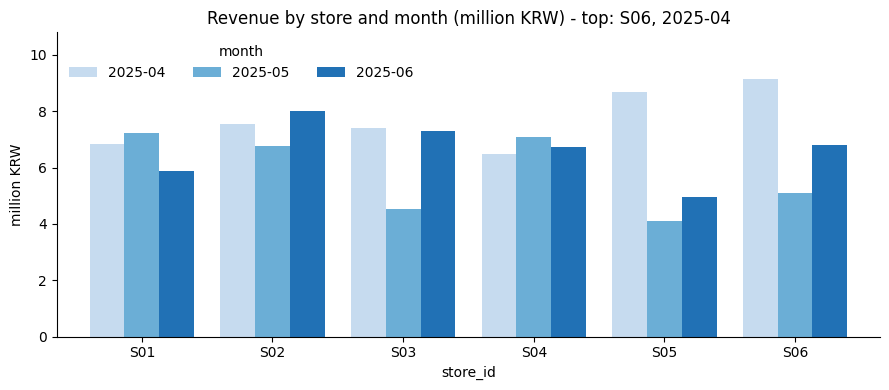

In [8]:
# wide 표 → long으로 펴서 매출 Top 3 (매장, 월)
top3 = store_month.stack().rename("revenue").sort_values(ascending=False).head(3).reset_index()
print("매출 Top 3 (매장, 월)")
display(top3)

ax = (store_month / 1e6).plot(kind="bar", figsize=(9, 4), width=0.8,
                      color=["#c6dbef", "#6baed6", "#2171b5"])
ax.set_title("Revenue by store and month (million KRW) - top: S06, 2025-04")
ax.set_xlabel("store_id"); ax.set_ylabel("million KRW")
ax.legend(title="month", frameon=False, ncol=3, loc="upper left")
ax.set_ylim(0, store_month.values.max() / 1e6 * 1.18)
ax.spines[["top", "right"]].set_visible(False)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

---
## EDA — 탐색적 데이터 분석

KPI 표 외에 데이터 구조 자체에서 확인할 점을 짚습니다.

In [9]:
print("[1] 실제 영업일:", sorted(bakery_clean["date"].dt.date.unique()),
      "→ 3개월이지만 날짜는 3일뿐 (월별 KPI = 사실상 그날 하루 매출)")

month_tot = bakery_clean.groupby("month")["revenue"].agg(["sum", "count"])
month_tot["share_pct"] = (month_tot["sum"] / month_tot["sum"].sum() * 100).round(1)
print("\n[2] 월별 매출 합계"); display(month_tot)

store_tot = bakery_clean.groupby("store_id")["revenue"].sum().sort_values(ascending=False)
print("[3] 매장별 3개월 총매출 (원)"); display(store_tot.to_frame("revenue"))

q50 = bakery_clean["quantity"] == 50
print(f"[4] quantity=50: {q50.sum()}건 ({q50.mean() * 100:.1f}% of rows) / "
      f"매출 비중 {bakery_clean.loc[q50, 'revenue'].sum() / bakery_clean['revenue'].sum() * 100:.1f}%")
print("    → 50개 주문을 빼면 매출 구조가 완전히 달라짐. 단체 주문인지 입력 오류인지 확인 전까지 유지")

print("\n[5] 상품별 · 수량별 매출 비중 (행 합계 = 1)")
display(pd.crosstab(bakery_clean["item"], bakery_clean["quantity"],
                    values=bakery_clean["revenue"], aggfunc="sum", normalize="index").round(2))

[1] 실제 영업일: [datetime.date(2025, 4, 1), datetime.date(2025, 5, 15), datetime.date(2025, 6, 20)] → 3개월이지만 날짜는 3일뿐 (월별 KPI = 사실상 그날 하루 매출)

[2] 월별 매출 합계


,sum,count,share_pct
month,,,
2025-04,46099000.0,586,38.2
2025-05,34862500.0,597,28.9
2025-06,39679000.0,601,32.9


[3] 매장별 3개월 총매출 (원)


,revenue
store_id,
S02,22296500.0
S06,21048000.0
S04,20321000.0
S01,19961500.0
S03,19270000.0
S05,17743500.0


[4] quantity=50: 277건 (15.5% of rows) / 매출 비중 80.4%
    → 50개 주문을 빼면 매출 구조가 완전히 달라짐. 단체 주문인지 입력 오류인지 확인 전까지 유지

[5] 상품별 · 수량별 매출 비중 (행 합계 = 1)


quantity,1,2,3,5,50
item,,,,,
샌드위치,0.02,0.05,0.04,0.07,0.82
식빵,0.03,0.05,0.05,0.07,0.80
케이크,0.03,0.06,0.05,0.06,0.80
쿠키,0.03,0.05,0.05,0.07,0.81
크루아상,0.03,0.07,0.06,0.07,0.78


---
## 코드 퀴즈

`item`이 `'케이크'`이고 `revenue >= 10000`인 행만 골라 `store_id`별 평균 revenue를 구한 뒤 Parquet으로 저장합니다.

In [10]:
cake_kpi = (
    bakery_clean
    .query("item == '케이크' and revenue >= 10000")
    .groupby("store_id")["revenue"]
    .mean()
    .round(0)
    .reset_index(name="avg_cake_revenue")
)
display(cake_kpi)

cake_kpi.to_parquet(OUT_DIR / "cake_kpi.parquet", index=False)
print("저장 완료:", OUT_DIR / "cake_kpi.parquet")

,store_id,avg_cake_revenue
0,S01,81722.0
1,S02,134550.0
2,S03,99488.0
3,S04,85946.0
4,S05,104395.0
5,S06,71805.0


저장 완료: outputs/cake_kpi.parquet


---
## 결정 로그 (Part 7)

각 단계 함수가 실행되면서 자동으로 기록한 결정입니다. 아래 셀 출력을 마크다운 표로 그대로 붙일 수 있습니다.

In [11]:
decision_log = pd.DataFrame(decisions)
display(decision_log)

md_table = "| 단계 | 액션 | 근거 | 결과 |\n|---|---|---|---|\n"
for d in decisions:
    md_table += f"| {d['step']} | {d['action']} | {d['reason']} | {d['result']} |\n"
display(Markdown(md_table))
print(md_table)

,step,action,reason,result
0,1. 중복 제거,완전 중복 행 drop (keep='first'),모든 값이 같은 행은 시스템 중복 입력으로 간주 (거래 ID·시각이 없어 다른 기준...,"321건 제거 (2,164 → 1,843)"
1,2. store_id 정제,str.strip(),' S01 '과 'S01'은 같은 매장. 공백 때문에 매장 매출이 둘로 쪼개지는 것 방지,매장 종류 7 → 6
2,3. item 표기 통일,'케익' → '케이크',같은 상품이 두 이름으로 나뉘면 상품별 매출 순위가 왜곡됨,"8건 변경, 상품 종류 6 → 5"
3,4. 날짜 파싱,"pd.to_datetime(format='mixed', errors='coerce')",월별 집계가 목적이라 datetime 필요. coerce는 실패를 숨기므로 NaT ...,NaT(파싱 실패) 0건
4,5. 환불 분리,revenue < 0 행을 refunds_bakery로 이동,환불일 수 있어 버리지 않고 별도 보관. 매출 집계에서는 제외,"환불 1건 보관 (-45,000원)"
5,6. 결측 처리,revenue 결측 행 제거,"매출 합산이 목적. 임의로 채우면 합계가 왜곡됨 (결제 로그 누락, MCAR 가정)",58건 제거


| 단계 | 액션 | 근거 | 결과 |
|---|---|---|---|
| 1. 중복 제거 | 완전 중복 행 drop (keep='first') | 모든 값이 같은 행은 시스템 중복 입력으로 간주 (거래 ID·시각이 없어 다른 기준이 없음) | 321건 제거 (2,164 → 1,843) |
| 2. store_id 정제 | str.strip() | ' S01 '과 'S01'은 같은 매장. 공백 때문에 매장 매출이 둘로 쪼개지는 것 방지 | 매장 종류 7 → 6 |
| 3. item 표기 통일 | '케익' → '케이크' | 같은 상품이 두 이름으로 나뉘면 상품별 매출 순위가 왜곡됨 | 8건 변경, 상품 종류 6 → 5 |
| 4. 날짜 파싱 | pd.to_datetime(format='mixed', errors='coerce') | 월별 집계가 목적이라 datetime 필요. coerce는 실패를 숨기므로 NaT 건수를 확인 | NaT(파싱 실패) 0건 |
| 5. 환불 분리 | revenue < 0 행을 refunds_bakery로 이동 | 환불일 수 있어 버리지 않고 별도 보관. 매출 집계에서는 제외 | 환불 1건 보관 (-45,000원) |
| 6. 결측 처리 | revenue 결측 행 제거 | 매출 합산이 목적. 임의로 채우면 합계가 왜곡됨 (결제 로그 누락, MCAR 가정) | 58건 제거 |


| 단계 | 액션 | 근거 | 결과 |
|---|---|---|---|
| 1. 중복 제거 | 완전 중복 행 drop (keep='first') | 모든 값이 같은 행은 시스템 중복 입력으로 간주 (거래 ID·시각이 없어 다른 기준이 없음) | 321건 제거 (2,164 → 1,843) |
| 2. store_id 정제 | str.strip() | ' S01 '과 'S01'은 같은 매장. 공백 때문에 매장 매출이 둘로 쪼개지는 것 방지 | 매장 종류 7 → 6 |
| 3. item 표기 통일 | '케익' → '케이크' | 같은 상품이 두 이름으로 나뉘면 상품별 매출 순위가 왜곡됨 | 8건 변경, 상품 종류 6 → 5 |
| 4. 날짜 파싱 | pd.to_datetime(format='mixed', errors='coerce') | 월별 집계가 목적이라 datetime 필요. coerce는 실패를 숨기므로 NaT 건수를 확인 | NaT(파싱 실패) 0건 |
| 5. 환불 분리 | revenue < 0 행을 refunds_bakery로 이동 | 환불일 수 있어 버리지 않고 별도 보관. 매출 집계에서는 제외 | 환불 1건 보관 (-45,000원) |
| 6. 결측 처리 | revenue 결측 행 제거 | 매출 합산이 목적. 임의로 채우면 합계가 왜곡됨 (결제 로그 누락, MCAR 가정) | 58건 제거 |



## 보고서 숫자 검증

아래 보고서의 숫자를 코드로 다시 계산한 값입니다. 데이터가 바뀌면 이 출력으로 보고서를 갱신하세요.

In [12]:
best = store_month.stack().idxmax()
n_dedup = len(bakery) - len(bakery.drop_duplicates())
check = {
    "원본 행 수": len(bakery),
    "정제 후 행 수": len(bakery_clean),
    "revenue 결측(원본)": f"{bakery['revenue'].isna().sum()}건 ({bakery['revenue'].isna().mean() * 100:.2f}%)",
    "revenue 결측(중복 제거 후)": int(bakery.drop_duplicates()["revenue"].isna().sum()),
    "완전 중복": n_dedup,
    "환불": f"{len(refunds_bakery)}건 ({refunds_bakery['revenue'].sum():,.0f}원)",
    "' S01 ' 공백": int((bakery['store_id'] == ' S01 ').sum()),
    "'케익'": int((bakery['item'] == '케익').sum()),
    "quantity=50": int((bakery['quantity'] == 50).sum()),
    "총매출": f"{bakery_clean['revenue'].sum():,.0f}원",
    "최고 (매장, 월)": f"{best[0]}, {best[1]} ({store_month.stack().max():,.0f}원)",
    "매출 1위 상품": f"{item_kpi.index[0]} ({item_kpi['total_revenue'].iloc[0]:,.0f}원)",
}
for k, v in check.items():
    print(f"{k:<20}: {v}")

원본 행 수              : 2164
정제 후 행 수            : 1784
revenue 결측(원본)      : 60건 (2.77%)
revenue 결측(중복 제거 후) : 58
완전 중복               : 321
환불                  : 1건 (-45,000원)
' S01 ' 공백          : 10
'케익'                : 8
quantity=50         : 315
총매출                 : 120,640,500원
최고 (매장, 월)          : S06, 2025-04 (9,156,000원)
매출 1위 상품            : 쿠키 (26,690,000원)


### 결정 로그 (마크다운 표)

| 단계 | 액션 | 근거 | 결과 |
|---|---|---|---|
| 1. 중복 제거 | 완전 중복 행 drop (keep='first') | 모든 값이 같은 행은 시스템 중복 입력으로 간주 (거래 ID·시각이 없어 다른 기준이 없음) | 321건 제거 (2,164 → 1,843) |
| 2. store_id 정제 | str.strip() | ' S01 '과 'S01'은 같은 매장. 공백 때문에 매장 매출이 둘로 쪼개지는 것 방지 | 매장 종류 7 → 6 |
| 3. item 표기 통일 | '케익' → '케이크' | 같은 상품이 두 이름으로 나뉘면 상품별 매출 순위가 왜곡됨 | 8건 변경, 상품 종류 6 → 5 |
| 4. 날짜 파싱 | pd.to_datetime(format='mixed', errors='coerce') | 월별 집계가 목적이라 datetime 필요. coerce는 실패를 숨기므로 NaT 건수를 확인 | NaT(파싱 실패) 0건 |
| 5. 환불 분리 | revenue < 0 행을 refunds_bakery로 이동 | 환불일 수 있어 버리지 않고 별도 보관. 매출 집계에서는 제외 | 환불 1건 보관 (−45,000원) |
| 6. 결측 처리 | revenue 결측 행 제거 | 매출 합산이 목적. 임의로 채우면 합계가 왜곡됨 (결제 로그 누락, MCAR 가정) | 58건 제거 |

---
# 빵셀러 데이터 정제·집계 보고서

## 1. 데이터 개요
- 출처: (가상) 빵셀러 베이커리 체인 운영 로그 (6개 매장 S01~S06, 상품 5종)
- 기간: 2025-04-01 ~ 2025-06-30 (3개월) — 단, 데이터에 실제로 있는 날짜는 04-01 · 05-15 · 06-20 사흘뿐
- 원본 행 수 / 정제 후 행 수: (2,164)행 → (1,784)행 (환불 1건은 `refunds_bakery`에 별도 보관, 정제 후 총매출 120,640,500원)

## 2. 발견한 품질 문제
- 결측: revenue 2.77% (60건, 중복 제거 후 58건)
- 중복: 완전 중복 321건 (심어 둔 4건 + 거래 ID·시각이 없어 값이 우연히 같아진 행)
- 이상치: quantity 50 (315건, 14.6%), revenue −45,000원 (1건) — IQR 이상치 비율은 revenue 17.3%, quantity 14.56%
- 표기 혼재: store_id `' S01 '` 공백 10건, item `'케익'` 8건 (`'케이크'`와 혼용), date_str 포맷 3종 (`2025-04-01` / `2025/04/01` / `20250401`)

## 3. 처리 결정과 근거 (5줄로)
1. 중복 행 (321)건 → 첫 행만 남기고 제거 (모든 값이 같은 행은 시스템 중복 입력으로 간주. 단, 정상 거래가 섞였을 수 있어 한계에 기록)
2. store_id 공백 → `str.strip()`으로 제거 (공백 때문에 S01 매출이 두 그룹으로 쪼개지는 것 방지, 매장 7종 → 6종)
3. item '케익' → '케이크' → 표준 표기로 통일 (같은 상품의 매출이 둘로 나뉘어 상품 순위가 왜곡되는 것 방지, 8건)
4. revenue 음수 → 별도 보관 (1)건 (−45,000원, 환불일 수 있어 삭제하지 않고 `refunds_bakery`로 분리)
5. revenue 결측 (58)건 → 제거 (이유: 매출 합산이 목적이라 임의로 채우면 합계가 왜곡되고, 결측률 2.77%로 영향이 작음. 결제 로그 누락에 따른 무작위 결측(MCAR)으로 가정)

## 4. 주요 KPI 결과 (2줄)
- (월·매장 관점) 가장 매출이 큰 매장과 그 월: S06, 2025-04 (9,156,000원) — 2위 S05 2025-04 (8,681,500원)
- (상품 관점) 매출 1위 상품: 쿠키 (26,690,000원) — 2위 샌드위치(26,297,000원)와 차이 39만 원으로 상위권이 근소함

## 5. 한계와 후속 작업
- 완전 중복 321건 중 심어 둔 것은 4건뿐 → 나머지는 같은 날 같은 상품을 같은 수량으로 판 정상 거래일 수 있음. 거래 ID 또는 시간대 컬럼을 원본에 추가해 중복 기준을 다시 정할 필요
- quantity=50 주문이 행의 15.5%인데 매출의 80.4%를 차지 → 단체 주문인지 입력 오류인지 확인 전까지는 KPI 해석에 주의 (이번엔 유지)
- 날짜가 3일뿐이라 "월별" KPI는 사실상 그날 하루 매출 → 일별 데이터가 쌓이면 월 단위 재집계 필요
- 환불 1건(−45,000원)의 발생 원인(매장 S06, 샌드위치) 확인, 환불이 쌓이면 분기별 환불률 분석
- item '케익'/'케이크' 외에 다른 표기 변종이 있는지, store_id에 다른 공백·대소문자 변종이 생기는지 실행마다 `value_counts()`로 점검
- 저장: `bakery_clean`은 Parquet이 CSV의 약 11.7% (8.2 KB vs 70.0 KB)이고 날짜형이 유지되어, 다음 분석가에게는 Parquet으로 넘김